# HW 8, Problem 2: Extended Kalman filter

Both models, with the truth, observations, $H$, $R$, $D$, and prior saved in Problem 1 (`data/hw8_twin_*.npz`); nothing is regenerated here.

## Setup

* **Forecast.** $m_k^f = \mathcal M_{k-1}(m_{k-1}^a)$ with the same numerical model map as the truth (`solve_ivp`, RK45, `rtol = atol = 1e-9`, over one observation window $\delta t = 0.1$). $\mathbf M_{k-1} = D\mathcal M_{k-1}(m_{k-1}^a)$ is the Jacobian of the **whole observation-window flow map**, not $Df$. It comes from the variational equations
$$\dot x = f(x), \qquad \dot\Phi = Df(x(t))\,\Phi, \qquad x(0) = m_{k-1}^a,\ \ \Phi(0) = I, \qquad \mathbf M_{k-1} = \Phi(\delta t),$$
integrated together as one $(n + n^2)$-dimensional ODE (1640 equations for the one-layer model, 930 for the two-layer model) with the same solver and tolerances. $Df$ is analytic (`jacobians.py`). $P_k^f = \mathbf M_{k-1}P_{k-1}^a\mathbf M_{k-1}^T$ since $Q_{k-1} = 0$.
* **Analysis** (`kalman.kf_analysis`, as in HW 7): $S_k = HP_k^fH^T + R$; the gain is applied by solving $S_kK_k^T = HP_k^f$ (no inverse); $m_k^a = m_k^f + K_k(y_k - Hm_k^f)$; Joseph update $P_k^a = (I - K_kH)P_k^f(I - K_kH)^T + K_kRK_k^T$. Both $P_k^f$ and $P_k^a$ are symmetrized, $P \leftarrow \tfrac12(P + P^T)$, after their relative asymmetry $\lVert P - P^T\rVert_F / \lVert P\rVert_F$ is recorded.
* **Positive semidefiniteness.** Checked on the dimensionless covariance $D^{-1}PD^{-1}$ (the state components have different scales in the two-layer model). Tolerance: $\lambda_{\min} \ge -n\,\varepsilon_{\text{mach}}\,\lambda_{\max}$, the size of roundoff error in computed eigenvalues of an $n \times n$ symmetric matrix.
* **Runtime.** Wall time of the whole cycle: forecasts of the mean, the variational (Jacobian) integrations, and the analyses, reported as the best of 3 identical runs. The Jacobian part is also reported separately.
* **Code.** `src/da_models/ekf.py` (`make_flow_jacobian`, `run_ekf`, `central_difference_check`); experiment settings in `src/da_models/hw8.py`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.stats import chi2

from da_models import hw8
from da_models.assimilation import make_propagator
from da_models.ekf import make_flow_jacobian, run_ekf, central_difference_check
from da_models.kalman import run_kf, synthetic_observations

DATA_DIR = Path("../data")   # adjust if running in Colab
NAMES = ("l96", "l96_2layer")
REPEATS = 3                  # timing: best of REPEATS identical runs

models = {name: hw8.load_model(name, DATA_DIR) for name in NAMES}
twins = {name: hw8.load_twin(name, DATA_DIR) for name in NAMES}
L = hw8.L
t_an = hw8.DT_OBS * np.arange(L + 1)      # t_0, ..., t_L
t_obs = t_an[1:]                          # t_1, ..., t_L

np.set_printoptions(precision=4, suppress=True, linewidth=110)
C = dict(truth="#0b0b0b", ekf="#2a78d6", free="#8c8a85", obs="#eb6834")
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

def time_avg_rmse(rmse):
    # sqrt( L^{-1} sum_{k=1}^{L} RMSE_k^2 ); rmse[0] is the initial time and is excluded
    return np.sqrt(np.mean(rmse[1:] ** 2))

## Checks

1. The analytic $Df$ agrees with central differences of the right-hand side ($h = 10^{-6}$) at the prior mean. The two-layer Jacobian is new in HW 8.
2. On a **linear** model $\dot x = Ax$ (random $6 \times 6$ matrix $A$, half the state observed, 30 analyses), `run_ekf` must reproduce `run_kf` with $\mathbf M = e^{A\,\delta t}$: the EKF is exact for linear dynamics. This tests the cycling and analysis code separately from the nonlinear models.

In [2]:
for name, mdl in models.items():
    x, p = mdl["m0"], mdl["params"]
    A = mdl["jac"](x, **p)
    h = 1e-6
    A_fd = np.column_stack([(mdl["rhs"](0, x + h * e, **p) - mdl["rhs"](0, x - h * e, **p)) / (2 * h)
                            for e in np.eye(mdl["n"])])
    print(f"{mdl['title']}: max |Df - central differences| / max |Df| = "
          f"{np.abs(A - A_fd).max() / np.abs(A).max():.1e}")

rng = np.random.default_rng(0)
A_lin = 0.5 * rng.standard_normal((6, 6)) - 0.3 * np.eye(6)
rhs_lin, jac_lin = (lambda t, x: A_lin @ x), (lambda x: A_lin)
prop_lin = make_propagator(rhs_lin, {}, hw8.DT_OBS, hw8.N_SUB, rtol=1e-11, atol=1e-11)
fj_lin = make_flow_jacobian(rhs_lin, jac_lin, {}, hw8.DT_OBS, hw8.N_SUB, rtol=1e-11, atol=1e-11)
M_lin, H_lin, R_lin = expm(A_lin * hw8.DT_OBS), np.eye(6)[::2], 0.5 * np.eye(3)
x_lin = [rng.standard_normal(6)]
for _ in range(30):
    x_lin.append(M_lin @ x_lin[-1])
x_lin = np.array(x_lin)
Y_lin = synthetic_observations(x_lin, H_lin, R_lin, rng)
e_lin = run_ekf(prop_lin, fj_lin, x_lin[0] + 0.3, 0.2 * np.eye(6), Y_lin, H_lin, R_lin)
k_lin = run_kf(M_lin, H_lin, R_lin, Y_lin, x_lin[0] + 0.3, 0.2 * np.eye(6))
print(f"\nlinear model, EKF vs KF: max |m_a difference| = {np.abs(e_lin['m_a'] - k_lin['m_a']).max():.1e}, "
      f"max |P_a difference| = {np.abs(e_lin['P_a'] - k_lin['P_a']).max():.1e}")

One-layer Lorenz-96: max |Df - central differences| / max |Df| = 3.9e-10
Two-layer Lorenz-96 (K = 10, J = 2): max |Df - central differences| / max |Df| = 4.1e-10

linear model, EKF vs KF: max |m_a difference| = 6.9e-12, max |P_a difference| = 1.2e-12


## Run the EKF

Each model runs once per repeat with identical inputs (the EKF has no random numbers), so the repeats give identical results and differ only in wall time.

In [3]:
def timed_ekf(mdl, Y, repeats=REPEATS):
    best = None
    for _ in range(repeats):
        out = run_ekf(mdl["propagate"], mdl["flow_jacobian"], mdl["m0"], mdl["P0"], Y, mdl["H"], mdl["R"])
        if best is None or out["wall_time"] < best["wall_time"]:
            best = out
    return best

ekf = {}
for name, mdl in models.items():
    out = timed_ekf(mdl, twins[name]["Y"])
    out["rmse"], out["spread"] = hw8.scaled_rmse_spread(out["m_a"], twins[name]["x_true"], mdl["D"], out["P_a"])
    ekf[name] = out
    status = "completed" if out["failed_at"] is None else f"FAILED at k = {out['failed_at']}: {out['message']}"
    print(f"{mdl['title']}: {status}; runtime {out['wall_time']:.2f} s "
          f"(variational/Jacobian integrations {out['jacobian_time']:.2f} s)")

One-layer Lorenz-96: completed; runtime 1.26 s (variational/Jacobian integrations 0.80 s)


Two-layer Lorenz-96 (K = 10, J = 2): completed; runtime 1.37 s (variational/Jacobian integrations 0.93 s)


## (a) Check of the flow-map Jacobian $\mathbf M_{k-1}$

**Method and numerical settings.**

* **Method.** $\mathbf M_{k-1}$ comes from the variational equations (see Setup): the state and $\Phi$ are integrated together over one observation window with `solve_ivp`, RK45, `rtol = atol = 1e-9`, and the analytic $Df$.
* **Check state.** One representative forecast state per model: the EKF analysis mean $m = m_{49}^a$, i.e. the forecast from $t_{49} = 4.9$ to $t_{50} = 5.0$. The cell asserts that the Jacobian checked is the same $\mathbf M_{49}$ the filter used.
* **Direction.** $q = Dw/\lVert w\rVert$ with $w \sim N(0, I)$ from `default_rng([513, 3, model])` (`hw8.rng_direction`), so $q$ perturbs every component in proportion to its scale.
* **Comparison.** $\mathbf M_{49}\,q$ against the central difference of the **whole observation-window flow map**,
$$\frac{\mathcal M(m + \epsilon q) - \mathcal M(m - \epsilon q)}{2\epsilon}, \qquad \epsilon = 10^{-1}, \dots, 10^{-9},$$
computed with the same model map and tolerances as the filter. Reported error: $\lVert \text{central difference} - \mathbf M_{49}q\rVert / \lVert\mathbf M_{49}q\rVert$.

The cell prints the relative errors. The figure adds three reference lines: a truncation slope $C\epsilon^2$ (matched at $\epsilon = 10^{-2}$), the cancellation estimate $\varepsilon_{\text{mach}}\lVert\mathcal M(m)\rVert / (2\epsilon\lVert\mathbf M q\rVert)$, and the solver tolerance $10^{-9}$.

=== One-layer Lorenz-96: m = m^a_49, |q| = 3.639, |Mq| = 4.413
  eps      :   1e-01    1e-02    1e-03    1e-04    1e-05    1e-06    1e-07    1e-08    1e-09
  rel. err.: 6.3e-05  6.4e-07  6.5e-09  4.9e-10  4.7e-10  1.7e-09  8.6e-09  1.4e-07  9.7e-07
  smallest error 4.7e-10 at eps = 1e-05



=== Two-layer Lorenz-96 (K = 10, J = 2): m = m^a_49, |q| = 1.939, |Mq| = 2.154
  eps      :   1e-01    1e-02    1e-03    1e-04    1e-05    1e-06    1e-07    1e-08    1e-09
  rel. err.: 5.4e-05  5.4e-07  5.5e-09  9.7e-10  9.7e-10  1.6e-09  9.6e-09  1.1e-07  1.2e-06
  smallest error 9.7e-10 at eps = 1e-04



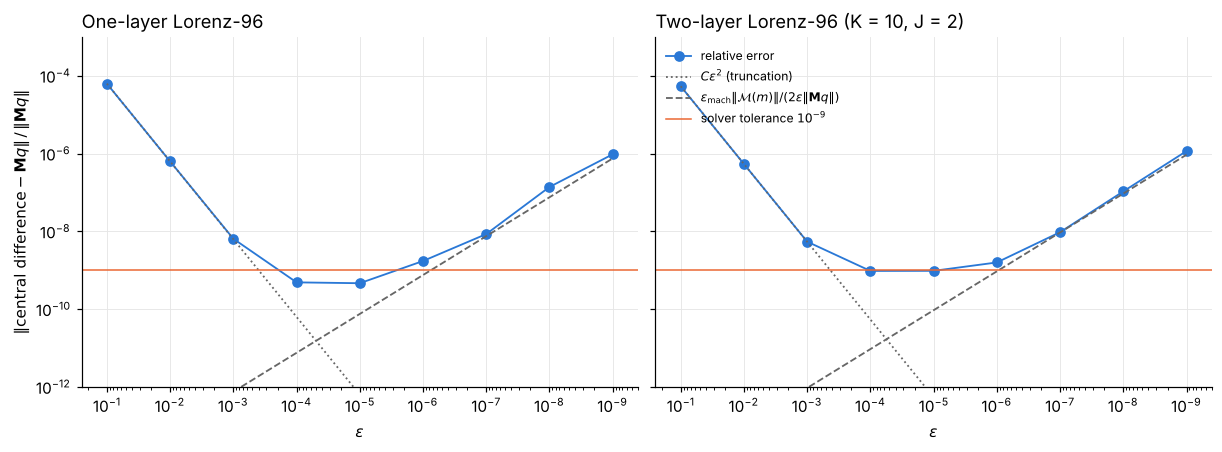

In [4]:
K_CHECK = 50                               # check the forecast that ends at t_50
EPS = 10.0 ** -np.arange(1, 10)
eps_mach = np.finfo(float).eps

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, (name, mdl) in zip(axes, models.items()):
    m = ekf[name]["m_a"][K_CHECK - 1]
    w = hw8.rng_direction(name).standard_normal(mdl["n"])
    q = mdl["D"] * w / np.linalg.norm(w)
    Mq, rel_err = central_difference_check(mdl["propagate"], mdl["flow_jacobian"], m, q, EPS)
    assert np.allclose(mdl["flow_jacobian"](m)[-1], ekf[name]["M"][K_CHECK - 1])   # the M the filter used

    print(f"=== {mdl['title']}: m = m^a_{K_CHECK - 1}, |q| = {np.linalg.norm(q):.3f}, |Mq| = {np.linalg.norm(Mq):.3f}")
    print("  eps      : " + "  ".join(f"{e:7.0e}" for e in EPS))
    print("  rel. err.: " + "  ".join(f"{r:7.1e}" for r in rel_err))
    print(f"  smallest error {rel_err.min():.1e} at eps = {EPS[rel_err.argmin()]:.0e}\n")

    norm_Mm = np.linalg.norm(mdl["propagate"](m)[-1])
    ax.loglog(EPS, rel_err, "o-", color=C["ekf"], label="relative error")
    ax.loglog(EPS, rel_err[1] * (EPS / EPS[1]) ** 2, ":", color="0.4", label=r"$C\epsilon^2$ (truncation)")
    ax.loglog(EPS, eps_mach * norm_Mm / (2 * EPS * np.linalg.norm(Mq)), "--", color="0.4",
              label=r"$\varepsilon_{\mathrm{mach}}\|\mathcal{M}(m)\| / (2\epsilon\|\mathbf{M}q\|)$")
    ax.axhline(hw8.SOLVER["rtol"], color=C["obs"], lw=1, label="solver tolerance $10^{-9}$")
    ax.set_title(mdl["title"], loc="left")
    ax.set_xlabel(r"$\epsilon$")
    ax.set_ylim(1e-12, 1e-3)
    ax.invert_xaxis()
axes[0].set_ylabel(r"$\|\mathrm{central\ difference} - \mathbf{M}q\| \,/\, \|\mathbf{M}q\|$")
axes[1].legend(loc="upper left", fontsize=8)
plt.show()

**Tolerance for the check.** *One or two sentences: the tolerance you accept and why, in terms of the solver tolerance and the cancellation error (the reference lines in the figure). The method, settings, and errors are reported above.*



## (b) Recorded quantities, covariance checks, and runtime

`run_ekf` records $m_k^f, P_k^f, m_k^a, P_k^a$ ($k = 0, \dots, L$), the Jacobians $\mathbf M_{k-1}$, gains $K_k$, innovations $d_k = y_k - Hm_k^f$, and $S_k$. The table summarizes the covariance checks over all $k$; the figure shows a first look at the scaled RMSE and spread (full comparison in Problem 4) and the normalized innovation squared $\mathrm{NIS}_k = d_k^TS_k^{-1}d_k$, whose mean under the filter's own assumptions is $p$, with the central 95% interval of $\chi^2_p$ shaded.

In [5]:
def scaled_eig_ratio(P, D):
    # smallest / largest eigenvalue of D^{-1} P D^{-1}
    ev = np.linalg.eigvalsh(P / np.outer(D, D))
    return ev[0] / ev[-1]

print(f"{'model':<38}{'runtime (s)':>12}{'Jacobian (s)':>13}{'max asym P_f':>14}{'max asym P_a':>14}"
      f"{'min lam/max lam P_f':>21}{'P_a':>11}{'tolerance':>11}{'PSD?':>6}")
for name, mdl in models.items():
    o = ekf[name]
    ok = slice(1, None) if o["failed_at"] is None else slice(1, o["failed_at"])
    ratio_f = min(scaled_eig_ratio(P, mdl["D"]) for P in o["P_f"][ok])
    ratio_a = min(scaled_eig_ratio(P, mdl["D"]) for P in o["P_a"][ok])
    tol = -mdl["n"] * eps_mach
    print(f"{mdl['title']:<38}{o['wall_time']:12.2f}{o['jacobian_time']:13.2f}{np.nanmax(o['asym_f']):14.1e}"
          f"{np.nanmax(o['asym_a']):14.1e}{ratio_f:21.1e}{ratio_a:11.1e}{tol:11.1e}"
          f"{'yes' if min(ratio_f, ratio_a) >= tol else 'NO':>6}")

model                                  runtime (s) Jacobian (s)  max asym P_f  max asym P_a  min lam/max lam P_f        P_a  tolerance  PSD?
One-layer Lorenz-96                           1.26         0.80       4.6e-16       3.0e-16             -3.3e-16   -3.2e-16   -8.9e-15   yes
Two-layer Lorenz-96 (K = 10, J = 2)           1.37         0.93       5.3e-16       2.1e-16             -3.5e-16   -1.9e-16   -6.7e-15   yes


One-layer Lorenz-96: time-aggregated RMSE 0.945 (free forecast 1.155), mean spread 0.097, mean NIS 224.4 (p = 20)
Two-layer Lorenz-96 (K = 10, J = 2): time-aggregated RMSE 0.062 (free forecast 0.220), mean spread 0.061, mean NIS 5.0 (p = 5)


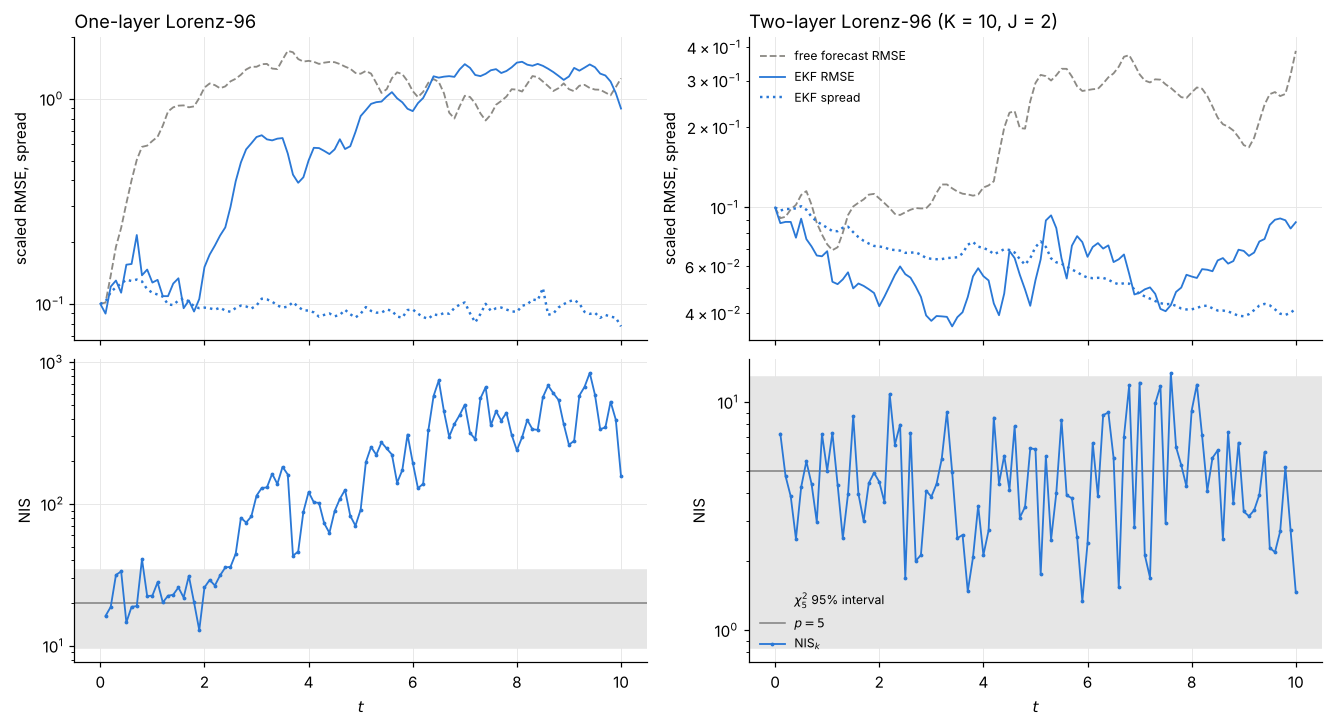

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, constrained_layout=True)
for j, (name, mdl) in enumerate(models.items()):
    o, tw = ekf[name], twins[name]
    rmse_free, _ = hw8.scaled_rmse_spread(tw["x_free"], tw["x_true"], mdl["D"])
    ax = axes[0, j]
    ax.semilogy(t_an, rmse_free, color=C["free"], ls="--", label="free forecast RMSE")
    ax.semilogy(t_an, o["rmse"], color=C["ekf"], label="EKF RMSE")
    ax.semilogy(t_an, o["spread"], color=C["ekf"], ls=":", lw=1.6, label="EKF spread")
    ax.set_title(mdl["title"], loc="left")
    ax.set_ylabel("scaled RMSE, spread")

    p = mdl["H"].shape[0]
    nis = np.einsum("ki,ki->k", o["innovation"], np.linalg.solve(o["S"], o["innovation"][..., None])[..., 0])
    lo, hi = chi2.ppf([0.025, 0.975], p)
    ax = axes[1, j]
    ax.axhspan(lo, hi, color="0.9", label=rf"$\chi^2_{{{p}}}$ 95% interval")
    ax.axhline(p, color="0.5", lw=1, label=f"$p = {p}$")
    ax.semilogy(t_obs, nis, ".-", color=C["ekf"], ms=3, label="NIS$_k$")
    ax.set_ylabel("NIS")
    ax.set_xlabel("$t$")
    print(f"{mdl['title']}: time-aggregated RMSE {time_avg_rmse(o['rmse']):.3f} "
          f"(free forecast {time_avg_rmse(rmse_free):.3f}), mean spread {o['spread'][1:].mean():.3f}, "
          f"mean NIS {nis.mean():.1f} (p = {p})")
axes[0, 1].legend(fontsize=8)
axes[1, 1].legend(fontsize=8)
plt.show()

## (c) How the EKF updates a hidden variable

For the analysis at $t_k$ (`K_SHOW`), the cell prints, for one hidden component $i$ per model (`HIDDEN`; change either to look at others): row $i$ of $K_k$ (one weight per observed component), the innovation $d_k = y_k - Hm_k^f$, the products $K_{k,ij}\,d_{k,j}$, and their sum, which is the analysis increment $m_{k,i}^a - m_{k,i}^f$. It also prints the forecast correlations between the hidden component and each observed component (from $P_k^f$), the quantities behind the row of $K_k$. The figure shows the same at `K_SHOW`, and the hidden component's increment against its forecast error $x_{k,i}^\dagger - m_{k,i}^f$ at every analysis.

In [7]:
K_SHOW = 50                                       # analysis index k, t_k = k * dt
HIDDEN = {"l96": "u1", "l96_2layer": "v0,1"}      # one hidden component per model

for name, mdl in models.items():
    o, tw = ekf[name], twins[name]
    k, i = K_SHOW, mdl["labels"].index(HIDDEN[name])
    obs_labels = [mdl["labels"][j] for j in mdl["observed"]]
    row, d = o["K"][k - 1][i], o["innovation"][k - 1]
    Pf = o["P_f"][k]
    sd = np.sqrt(np.diag(Pf))
    corr = Pf[i, mdl["observed"]] / (sd[i] * sd[mdl["observed"]])
    print(f"=== {mdl['title']}: analysis k = {k} (t = {t_an[k]:.1f}), hidden component {HIDDEN[name]} ===")
    print(f"truth {tw['x_true'][k, i]:.4f}   forecast {o['m_f'][k, i]:.4f}   analysis {o['m_a'][k, i]:.4f}")
    print(f"{'observed':>9}{'corr_f':>9}{'K row':>10}{'d_k':>9}{'K*d':>10}")
    for lab, c, kk, dd in zip(obs_labels, corr, row, d):
        print(f"{lab:>9}{c:9.3f}{kk:10.4f}{dd:9.3f}{kk * dd:10.4f}")
    print(f"sum of K*d = {row @ d:.4f};  m_a - m_f = {o['m_a'][k, i] - o['m_f'][k, i]:.4f}\n")

=== One-layer Lorenz-96: analysis k = 50 (t = 5.0), hidden component u1 ===
truth 1.4040   forecast 3.4287   analysis 2.5996
 observed   corr_f     K row      d_k       K*d
       u0   -0.443   -0.0236    1.310   -0.0309
       u2    0.703    0.0339    1.960    0.0664
       u4    0.562    0.0440   -0.470   -0.0207
       u6    0.679    0.0795   -2.934   -0.2333
       u8   -0.771   -0.0757    4.444   -0.3364
      u10   -0.758   -0.0757    0.482   -0.0365
      u12    0.545    0.0719   -2.852   -0.2050
      u14    0.392    0.0173   -0.224   -0.0039
      u16   -0.031   -0.0059   -2.091    0.0123
      u18   -0.084   -0.0055   -3.240    0.0178
      u20    0.040    0.0040    2.831    0.0113
      u22   -0.028   -0.0039    0.816   -0.0032
      u24   -0.077   -0.0111    3.907   -0.0433
      u26   -0.123   -0.0088   -3.796    0.0334
      u28   -0.094   -0.0152    0.962   -0.0147
      u30   -0.058   -0.0063    1.517   -0.0096
      u32   -0.114   -0.0136   -1.374    0.0187
      u34  

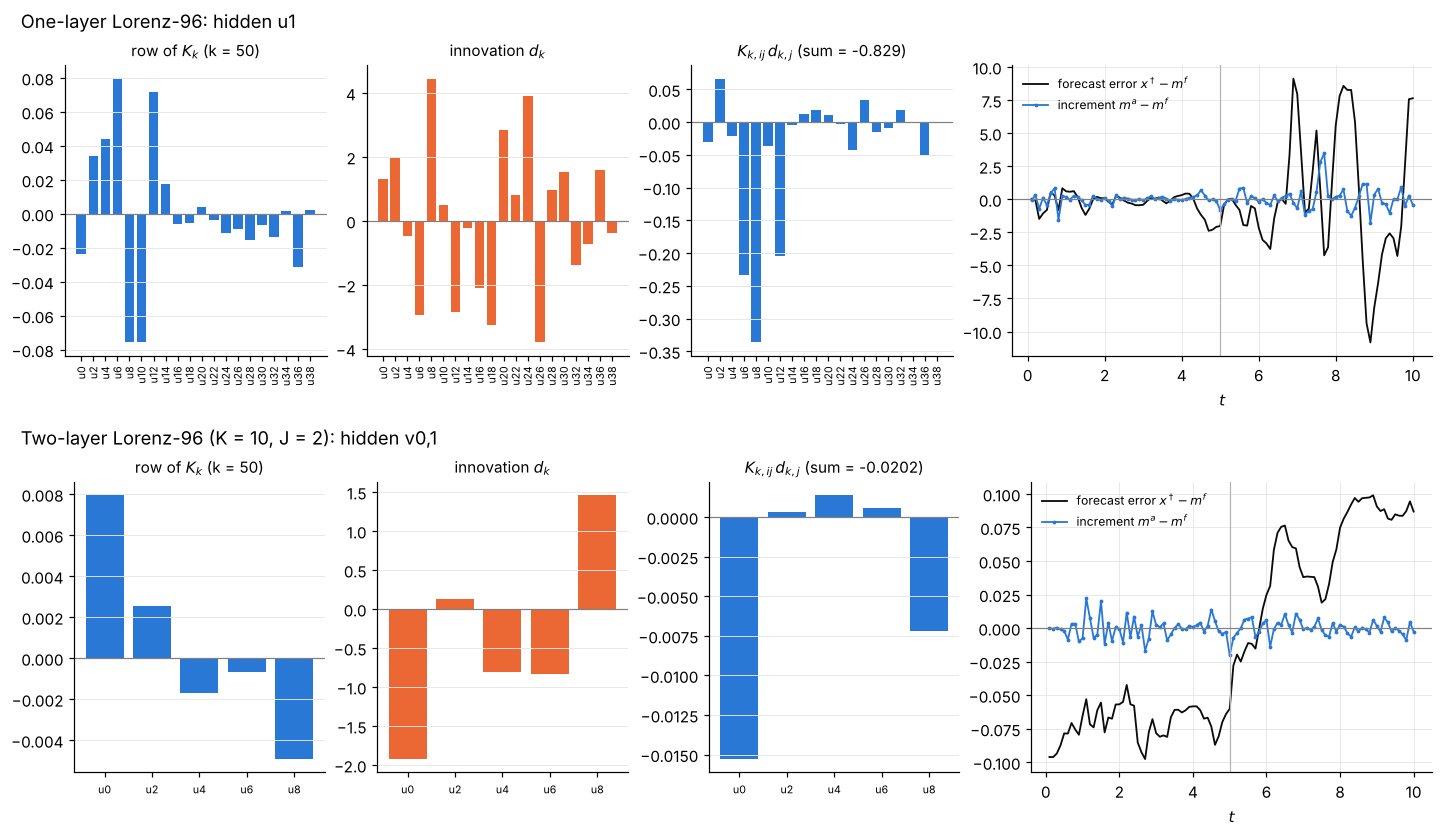

In [8]:
fig = plt.figure(figsize=(13, 7.5), constrained_layout=True)
sub = fig.subfigures(2, 1)
for r, (name, mdl) in enumerate(models.items()):
    o, tw = ekf[name], twins[name]
    i = mdl["labels"].index(HIDDEN[name])
    obs_labels = [mdl["labels"][j] for j in mdl["observed"]]
    row, d = o["K"][K_SHOW - 1][i], o["innovation"][K_SHOW - 1]
    ax_K, ax_d, ax_c, ax_t = sub[r].subplots(1, 4, width_ratios=[1, 1, 1, 1.6])
    sub[r].suptitle(f"{mdl['title']}: hidden {HIDDEN[name]}", x=0.01, ha="left")
    x = np.arange(len(obs_labels))
    ax_K.bar(x, row, color=C["ekf"])
    ax_K.set_title(f"row of $K_k$ (k = {K_SHOW})", fontsize=10)
    ax_d.bar(x, d, color=C["obs"])
    ax_d.set_title("innovation $d_k$", fontsize=10)
    ax_c.bar(x, row * d, color=C["ekf"])
    ax_c.set_title(rf"$K_{{k,ij}}\,d_{{k,j}}$ (sum = {row @ d:.3g})", fontsize=10)
    for ax in (ax_K, ax_d, ax_c):
        ax.set_xticks(x, obs_labels, rotation=90 if len(x) > 8 else 0, fontsize=7)
        ax.axhline(0, color="0.5", lw=0.8)
        ax.grid(axis="x", visible=False)
    incr = o["m_a"][1:, i] - o["m_f"][1:, i]
    ferr = tw["x_true"][1:, i] - o["m_f"][1:, i]
    ax_t.plot(t_obs, ferr, color=C["truth"], label=r"forecast error $x^\dagger - m^f$")
    ax_t.plot(t_obs, incr, ".-", color=C["ekf"], ms=3, label=r"increment $m^a - m^f$")
    ax_t.axvline(t_an[K_SHOW], color="0.7", lw=0.8)
    ax_t.axhline(0, color="0.5", lw=0.8)
    ax_t.set_xlabel("$t$")
    ax_t.legend(fontsize=8)
plt.show()

**Answer to 2(c).** *Explain what the EKF approximates in a nonlinear forecast and why linear observations do not make the full filtering problem Gaussian. Use the hidden-state row of $K_k$ and its innovation (above) to explain how that hidden variable is updated.*



## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 2: the `ekf.py` module, the two-layer Jacobian in `jacobians.py`, additions to `hw8.py`, and the code cells in this notebook. The tolerance justification in 2(a) and the answer to 2(c) are my own.